# 01 — Data acquisition

NDVI, LST and SPEI over the delineated olive orchard at Jendouba, March 2000 to
December 2024. The study area is a polygon rather than a single pixel, so each value
is an area-weighted mean over the orchard.

| Variable | Product | Resolution | Cadence |
|---|---|---|---|
| NDVI | MODIS MOD13Q1 v061 | 250 m | 16-day |
| LST | MODIS MOD11A2 v061, daytime | 1 km | 8-day |
| SPEI 1, 3, 6, 12, 24, 48 months | CSIC SPEIbase v2.11 | 0.5° | monthly |

The record starts in March 2000, the first full month of MOD13Q1, and ends in
December 2024, the last month of SPEIbase v2.11. The Earth Engine project is read
from the `EE_PROJECT` environment variable.

Input: `olive-jendouba-polygon.geojson` · Output: `data/raw/`

In [1]:
import json
import os

import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Earth Engine project id from the environment: export EE_PROJECT=<your project>
ee.Initialize(project=os.environ.get("EE_PROJECT"))

with open("../olive-jendouba-polygon.geojson") as f:
    gj = json.load(f)

AREA = ee.Geometry.Polygon(gj["features"][0]["geometry"]["coordinates"])
CENTROID = AREA.centroid(maxError=1)

START, END = "2000-03-01", "2024-12-31"

area_m2 = AREA.area().getInfo()
print(f"area {area_m2:,.0f} m2 = {area_m2 / 1e6:.3f} km2")
print(f"  MODIS 250 m : {area_m2 / 250**2:5.1f} pixels")
print(f"  MODIS 1 km  : {area_m2 / 1000**2:5.2f} pixels")

area 644,387 m2 = 0.644 km2
  MODIS 250 m :  10.3 pixels
  MODIS 1 km  :  0.64 pixels


## NDVI — MODIS MOD13Q1

Area-weighted spatial mean over the polygon. The mean is used rather than the median
because it is additive, so the decomposed components still sum to the series after
monthly aggregation. Spatial standard deviation and pixel count are kept per date.

Pixels are screened individually before the mean: only those with `SummaryQA` = 0
(good) are kept. Marginal pixels (1) agree closely with good ones when both occur in
a composite, but a composite made of marginal pixels alone can be cloud-contaminated.

In [2]:
def extract(collection, band, scale, name, prepare=None):
    """Spatial mean, spread and pixel count over the orchard, per date."""
    ic = (ee.ImageCollection(collection)
            .filterDate(START, END)
            .filterBounds(AREA))
    ic = ic.map(prepare) if prepare else ic.select(band)

    reducer = (ee.Reducer.mean()
                 .combine(ee.Reducer.stdDev(), sharedInputs=True)
                 .combine(ee.Reducer.count(), sharedInputs=True))

    def sample(img):
        stats = img.reduceRegion(reducer=reducer, geometry=AREA, scale=scale)
        return ee.Feature(None, {
            "date": img.date().format("YYYY-MM-dd"),
            name: stats.get(f"{band}_mean"),
            f"{name}_sd": stats.get(f"{band}_stdDev"),
            f"{name}_n": stats.get(f"{band}_count"),
        })

    rows = ee.FeatureCollection(ic.map(sample)).getInfo()["features"]
    df = pd.DataFrame([r["properties"] for r in rows])
    df["date"] = pd.to_datetime(df["date"])
    return df.sort_values("date").reset_index(drop=True)


# SummaryQA per pixel: 0 good, 1 marginal, 2 snow or ice, 3 cloudy.
# Only good pixels are kept, before the area mean. Marginal pixels agree with good
# ones when both are present, but a composite made of marginal pixels alone can be
# cloud-contaminated.
def good_pixels(img):
    return (img.select("NDVI").updateMask(img.select("SummaryQA").eq(0))
               .copyProperties(img, ["system:time_start"]))


ndvi = extract("MODIS/061/MOD13Q1", "NDVI", 250, "NDVI", prepare=good_pixels)
ndvi[["NDVI", "NDVI_sd"]] *= 0.0001

print(len(ndvi), "composites,",
      ndvi.date.min().date(), "->", ndvi.date.max().date())
print(ndvi[["NDVI", "NDVI_sd", "NDVI_n"]].describe().round(4))

571 composites, 2000-03-05 -> 2024-12-18
           NDVI   NDVI_sd    NDVI_n
count  556.0000  556.0000  571.0000
mean     0.4483    0.0415   17.5849
std      0.1715    0.0167    3.0997
min      0.2144    0.0151    0.0000
25%      0.2941    0.0286   18.0000
50%      0.3823    0.0382   18.0000
75%      0.6048    0.0517   18.0000
max      0.7901    0.1032   20.0000


## LST — MODIS MOD11A2

The orchard covers 0.64 of a 1 km pixel and straddles four, so LST cannot be
isolated to the study area.

In [3]:
lst = extract("MODIS/061/MOD11A2", "LST_Day_1km", 1000, "LST")
lst[["LST", "LST_sd"]] *= 0.02
lst["LST"] -= 273.15

print(len(lst), "composites,",
      lst.date.min().date(), "->", lst.date.max().date())
print(lst[["LST", "LST_sd", "LST_n"]].describe().round(3))
print("\nmissing:", lst["LST"].isna().sum())

1141 composites, 2000-03-05 -> 2024-12-26
            LST    LST_sd     LST_n
count  1133.000  1133.000  1141.000
mean     28.893     0.424     3.955
std      11.796     0.421     0.373
min       3.283     0.000     0.000
25%      17.833     0.166     4.000
50%      28.372     0.279     4.000
75%      39.809     0.534     4.000
max      52.333     3.824     4.000

missing: 8


## SPEI — CSIC SPEIbase v2.11

Scales of 1, 3, 6 and 12 months rather than the 1 to 4 of the source, following the
Mediterranean literature (Gouveia et al., 2017), and 24 and 48 months to test whether
droughts two and four years earlier still affect the orchard. At 0.5° the polygon is too small for
an area-weighted reduction, so the containing cell is sampled at the centroid.

In [4]:
SPEI_BANDS = ["SPEI_01_month", "SPEI_03_month", "SPEI_06_month", "SPEI_12_month",
              "SPEI_24_month", "SPEI_48_month"]
SPEI_COLS = [f"SPEI_{int(b[5:7])}" for b in SPEI_BANDS]

spei_ic = (ee.ImageCollection("CSIC/SPEI/2_11")
             .filterDate(START, END)
             .filterBounds(AREA)
             .select(SPEI_BANDS))


def sample_spei(img):
    stats = img.reduceRegion(ee.Reducer.first(), CENTROID, 55660)
    return ee.Feature(None, stats.set("date", img.date().format("YYYY-MM-dd")))


rows = ee.FeatureCollection(spei_ic.map(sample_spei)).getInfo()["features"]
spei = pd.DataFrame([r["properties"] for r in rows])
spei["date"] = pd.to_datetime(spei["date"])
spei = (spei.rename(columns=dict(zip(SPEI_BANDS, SPEI_COLS)))
            .sort_values("date").reset_index(drop=True))

print(len(spei), "months,", spei.date.min().date(), "->", spei.date.max().date())
print(spei[SPEI_COLS].describe().round(3))

298 months, 2000-03-01 -> 2024-12-01
        SPEI_1   SPEI_3   SPEI_6  SPEI_12  SPEI_24  SPEI_48
count  298.000  298.000  298.000  298.000  298.000  298.000
mean    -0.278   -0.350   -0.406   -0.492   -0.636   -0.806
std      1.047    1.043    1.049    1.095    1.090    1.039
min     -2.225   -2.612   -2.637   -2.802   -2.884   -3.101
25%     -1.078   -1.194   -1.234   -1.383   -1.433   -1.487
50%     -0.360   -0.362   -0.400   -0.524   -0.739   -0.910
75%      0.534    0.415    0.376    0.315    0.075   -0.195
max      2.235    2.448    2.372    2.055    1.971    1.766


## Quality screening

After the per-pixel mask, a composite is kept only if at least half of the study
area's pixels are good; otherwise it is set to missing and interpolated in
notebook 02. The earlier rule, which dropped a composite when the area-averaged
`SummaryQA` reached 2, is shown for comparison: it kept composites in which most
pixels were flagged but the average stayed just below 2. LST retrieval error is
checked from `QC_Day`.

In [5]:
qa = extract("MODIS/061/MOD13Q1", "SummaryQA", 250, "QA")[["date", "QA", "QA_n"]]
ndvi = ndvi.drop(columns=["QA", "QA_n"], errors="ignore").merge(qa, on="date", how="left")

# share of the study area's pixels left after the per-pixel mask
ndvi["valid_share"] = ndvi["NDVI_n"].fillna(0) / ndvi["QA_n"]
MIN_VALID = 0.5
DROP = ndvi["valid_share"] < MIN_VALID
OLD_RULE = ndvi["QA"] >= 2                      # earlier rule: area-mean flag >= 2

print(f"pixels removed by the mask: {1 - ndvi.NDVI_n.sum() / ndvi.QA_n.sum():.1%} of all pixel-dates")
print(f"composites with fewer than {MIN_VALID:.0%} good pixels, dropped: {DROP.sum()} of {len(ndvi)}")
print(f"composites the earlier area-mean rule would drop: {OLD_RULE.sum()}")
print(f"  dropped now but kept by the old rule: {(DROP & ~OLD_RULE).sum()}\n")
print(ndvi.loc[DROP, ["date", "NDVI", "valid_share", "QA"]]
          .assign(date=lambda t: t["date"].dt.date)
          .round(3).to_string(index=False))

ndvi.loc[DROP, ["NDVI", "NDVI_sd"]] = np.nan


def lst_quality(img):
    qc = img.select("QC_Day")
    flags = ee.Image.cat([qc.bitwiseAnd(3).rename("mandatory"),
                          qc.rightShift(6).bitwiseAnd(3).rename("error")])
    stats = flags.reduceRegion(ee.Reducer.mean(), AREA, 1000)
    return ee.Feature(None, stats.set("date", img.date().format("YYYY-MM-dd")))


rows = ee.FeatureCollection(
    ee.ImageCollection("MODIS/061/MOD11A2")
      .filterDate(START, END).filterBounds(AREA).map(lst_quality)
).getInfo()["features"]
lst_qc = pd.DataFrame([r["properties"] for r in rows])

print(f"\nLST error flag, area-weighted (0: <=1 K, 1: <=2 K, 2: <=3 K, 3: >3 K)")
print(f"  max over record {lst_qc['error'].max():.2f}")
print(f"  composites with estimated error above 2 K: {(lst_qc['error'] > 1).sum()}")

pixels removed by the mask: 3.2% of all pixel-dates
composites with fewer than 50% good pixels, dropped: 18 of 571
composites the earlier area-mean rule would drop: 8
  dropped now but kept by the old rule: 10

      date  NDVI  valid_share    QA
2000-03-21   NaN        0.000 3.000
2000-09-29 0.229        0.278 0.655
2001-11-17   NaN        0.000 3.000
2001-12-19   NaN        0.000 1.000
2002-03-22   NaN        0.000 3.000
2004-02-18   NaN        0.000 1.000
2004-12-18   NaN        0.000 3.000
2005-02-02   NaN        0.000 1.000
2009-02-02   NaN        0.000 1.000
2012-02-02   NaN        0.000 3.000
2018-11-17   NaN        0.000 1.000
2020-03-21 0.726        0.444 0.690
2021-03-06   NaN        0.000 1.000
2022-03-22   NaN        0.000 3.000
2023-05-09   NaN        0.000 1.000
2023-05-25 0.347        0.222 0.741
2023-12-03   NaN        0.000 3.000
2024-02-18   NaN        0.000 3.000



LST error flag, area-weighted (0: <=1 K, 1: <=2 K, 2: <=3 K, 3: >3 K)
  max over record 1.00
  composites with estimated error above 2 K: 0


## Monthly aggregation

In [6]:
ndvi_monthly = ndvi.set_index("date")[["NDVI", "NDVI_sd"]].resample("MS").mean()
lst_monthly  = lst.set_index("date")[["LST", "LST_sd"]].resample("MS").mean()

spei_monthly = spei.set_index("date")[SPEI_COLS]
spei_monthly.index = spei_monthly.index.to_period("M").to_timestamp()

master = ndvi_monthly.join(lst_monthly).join(spei_monthly, how="inner")

print(master.shape)
print(master.isna().sum().to_string())
print(master.head(3).round(4))

(298, 10)
NDVI       1
NDVI_sd    1
LST        0
LST_sd     0
SPEI_1     0
SPEI_3     0
SPEI_6     0
SPEI_12    0
SPEI_24    0
SPEI_48    0
              NDVI  NDVI_sd      LST  LST_sd  SPEI_1  SPEI_3  SPEI_6  SPEI_12  \
date                                                                            
2000-03-01  0.7023   0.0561  23.3282  0.3356 -1.7357 -2.2339 -1.4298  -1.8030   
2000-04-01  0.5430   0.0437  28.9590  0.3494 -0.6947 -1.9320 -1.2856  -1.6968   
2000-05-01  0.3377   0.0354  36.0573  0.3616  0.7090 -1.1561 -1.8439  -1.4755   

            SPEI_24  SPEI_48  
date                          
2000-03-01  -1.2212  -1.1153  
2000-04-01  -1.3100  -1.3724  
2000-05-01  -1.2159  -1.4246  


## Saving

In [7]:
ndvi.drop(columns=["QA_n"]).to_csv("../data/raw/orchard_ndvi_16day.csv", index=False)
lst.to_csv("../data/raw/orchard_lst_8day.csv", index=False)
spei.to_csv("../data/raw/orchard_spei_monthly.csv", index=False)
master.to_csv("../data/raw/orchard_monthly.csv")

print("16-day NDVI", ndvi.shape,
      "| 8-day LST", lst.shape,
      "| SPEI", spei.shape,
      "| monthly", master.shape)

16-day NDVI (571, 7) | 8-day LST (1141, 4) | SPEI (298, 7) | monthly (298, 10)


## Validation

| # | Check | Expectation |
|---|---|---|
| 1 | Seasonal phasing | LST peaks in summer, NDVI troughs in the same months |
| 2 | NDVI–LST coupling | strong negative correlation |
| 3 | Drought years | negative annual SPEI in the reported drought years |
| 4 | Spatial uniformity | within-orchard spread small against the seasonal range |
| 5 | Land-cover stability | no canopy-establishment signal |

### Checks 1, 2 and 4

In [8]:
clim = master.groupby(master.index.month)[["NDVI", "LST"]].mean().round(3)
print(clim.to_string())

print(f"\nNDVI peaks month {clim['NDVI'].idxmax():2d}, troughs month {clim['NDVI'].idxmin():2d}")
print(f"LST  peaks month {clim['LST'].idxmax():2d}, troughs month {clim['LST'].idxmin():2d}")
print(f"NDVI climatological amplitude: {clim['NDVI'].max() - clim['NDVI'].min():.3f}")

print(f"\nNDVI vs LST, same month: r = {master['NDVI'].corr(master['LST']):.3f}")
print(f"within-orchard NDVI sd: mean {master.NDVI_sd.mean():.4f}, "
      f"max {master.NDVI_sd.max():.4f}")
print(f"range of monthly NDVI:  {master.NDVI.max() - master.NDVI.min():.4f}")

       NDVI     LST
date               
1     0.614  13.946
2     0.681  15.679
3     0.702  20.332
4     0.610  25.562
5     0.380  32.981
6     0.298  41.111
7     0.273  45.398
8     0.279  44.300
9     0.300  37.540
10    0.339  31.211
11    0.419  21.909
12    0.501  15.105

NDVI peaks month  3, troughs month  7
LST  peaks month  7, troughs month  1
NDVI climatological amplitude: 0.429

NDVI vs LST, same month: r = -0.817
within-orchard NDVI sd: mean 0.0422, max 0.0993
range of monthly NDVI:  0.5527


### Check 3 — drought years and spatial outliers

In [9]:
annual = master.groupby(master.index.year)[SPEI_COLS].mean().round(2)
print(annual.to_string())

print("\nhighest within-orchard spread:")
print(master.nlargest(6, "NDVI_sd")[["NDVI", "NDVI_sd"]].round(4))

      SPEI_1  SPEI_3  SPEI_6  SPEI_12  SPEI_24  SPEI_48
date                                                   
2000   -0.47   -0.76   -1.11    -1.52    -1.25    -1.44
2001   -0.39   -0.51   -0.61    -0.70    -1.47    -1.20
2002   -0.10   -0.44   -1.01    -1.76    -1.65    -1.96
2003    0.16    0.65    1.16     1.78     0.05    -1.08
2004    0.14    0.40    0.66     0.80     1.79     0.05
2005   -0.01    0.07    0.37     0.95     1.18     0.86
2006   -0.27   -0.33   -0.35    -0.13     0.56     1.59
2007   -0.12    0.03    0.03    -0.37    -0.42     0.55
2008   -0.49   -0.70   -1.00    -1.21    -1.12    -0.46
2009    0.06    0.44    0.73     0.88    -0.28    -0.50
2010    0.05    0.04   -0.08    -0.40     0.31    -0.62
2011    0.09    0.29    0.57     0.66     0.14    -0.11
2012   -0.48   -0.60   -0.46    -0.04     0.39     0.48
2013    0.06   -0.14   -0.43    -0.94    -0.73    -0.44
2014   -0.42   -0.59   -0.48    -0.24    -0.86    -0.36
2015   -0.26   -0.15   -0.04     0.17    -0.11  

### Input series

Grey: the 2022–2024 test period.

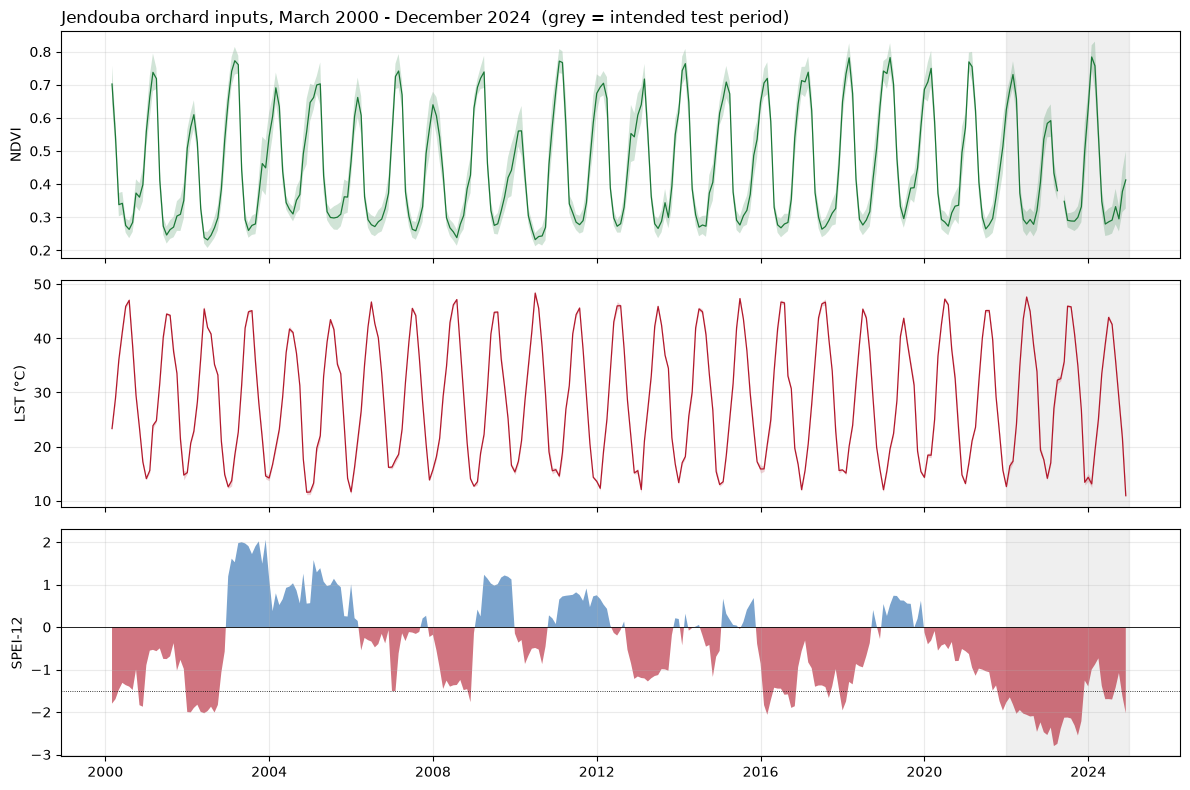

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
d = master.index

TEST_START, TEST_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31")
for ax in axes:
    ax.axvspan(TEST_START, TEST_END, color="grey", alpha=0.12, zorder=0)
    ax.grid(alpha=0.25)

axes[0].plot(d, master["NDVI"], lw=0.9, color="#1b7837")
axes[0].fill_between(d, master["NDVI"] - master["NDVI_sd"],
                        master["NDVI"] + master["NDVI_sd"],
                     color="#1b7837", alpha=0.20, lw=0)
axes[0].set_ylabel("NDVI")

axes[1].plot(d, master["LST"], lw=0.9, color="#b2182b")
axes[1].fill_between(d, master["LST"] - master["LST_sd"],
                        master["LST"] + master["LST_sd"],
                     color="#b2182b", alpha=0.20, lw=0)
axes[1].set_ylabel("LST (°C)")

s = master["SPEI_12"]
axes[2].fill_between(d, s, 0, where=s < 0, color="#b2182b", alpha=0.6,
                     lw=0, interpolate=True)
axes[2].fill_between(d, s, 0, where=s >= 0, color="#2166ac", alpha=0.6,
                     lw=0, interpolate=True)
axes[2].axhline(0, color="k", lw=0.6)
axes[2].axhline(-1.5, color="k", lw=0.6, ls=":")
axes[2].set_ylabel("SPEI-12")

axes[0].set_title("Jendouba orchard inputs, March 2000 - December 2024  "
                  "(grey = intended test period)", loc="left")
fig.tight_layout()
fig.savefig("../figures/01_input_series.png", dpi=150, bbox_inches="tight")
plt.show()

### Check 5 — land-cover stability

The July–September minimum isolates the woody canopy once the herbaceous layer has
died. An establishing orchard would raise it by 0.15 or more.

summer floor:  slope +0.00090/yr   p 0.0869   change over record +0.022
winter peak:  slope +0.00231/yr   p 0.1924   change over record +0.055


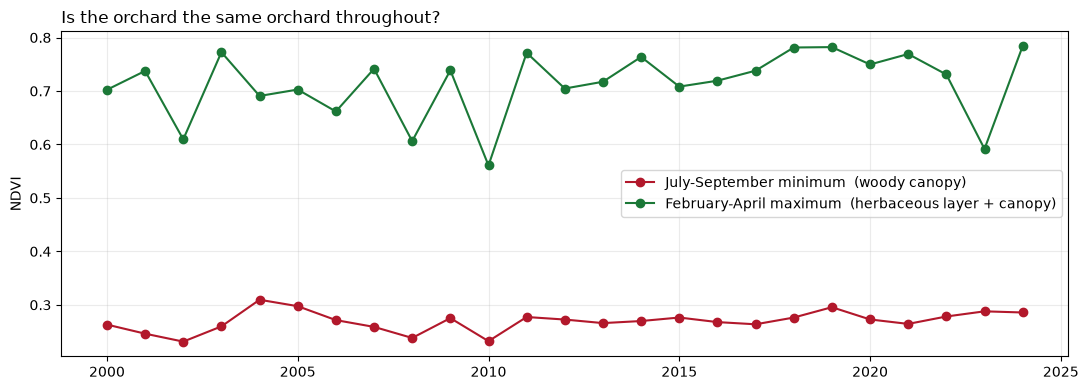

In [11]:
summer = master[master.index.month.isin([7, 8, 9])]
floor = summer.groupby(summer.index.year)["NDVI"].min()

winter = master[master.index.month.isin([2, 3, 4])]
ceiling = winter.groupby(winter.index.year)["NDVI"].max()

for label, s in [("summer floor", floor), ("winter peak", ceiling)]:
    r = linregress(s.index, s.values)
    print(f"{label}:  slope {r.slope:+.5f}/yr   p {r.pvalue:.4f}   "
          f"change over record {r.slope * (s.index[-1] - s.index[0]):+.3f}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(floor.index, floor.values, "o-", color="#b2182b",
        label="July-September minimum  (woody canopy)")
ax.plot(ceiling.index, ceiling.values, "o-", color="#1b7837",
        label="February-April maximum  (herbaceous layer + canopy)")
ax.set_ylabel("NDVI")
ax.grid(alpha=0.25)
ax.legend(loc="center right")
ax.set_title("Is the orchard the same orchard throughout?", loc="left")
fig.tight_layout()
fig.savefig("../figures/01_land_cover_stability.png", dpi=150, bbox_inches="tight")
plt.show()